In [1]:
from astropy.utils import iers
iers.conf.auto_download = False

import sys
from pathlib import Path

# Jupyter runs a notebook with its own folder (Notebooks/) as working directory,
# so step up one level if Src/ is not visible from here.
ROOT = Path.cwd()
if not (ROOT / "Src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "Src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

from paths import RAW_HMI, PROCESSED
from hmi import fits_name

# Standard test image: 2014-10-23 00:00 TAI (AR 12192 is large here)
T_REC_TEST = "2014.10.23_00:00:00_TAI"
test_path = RAW_HMI / fits_name(T_REC_TEST)
print(test_path.name, "| exists:", test_path.exists())

hmi.ic_720s.20141023_000000_TAI.1.continuum.fits | exists: True


[<astropy.io.fits.hdu.image.PrimaryHDU object at 0x1384da650>, <astropy.io.fits.hdu.compressed.compressed.CompImageHDU object at 0x1384c5350>]
[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]


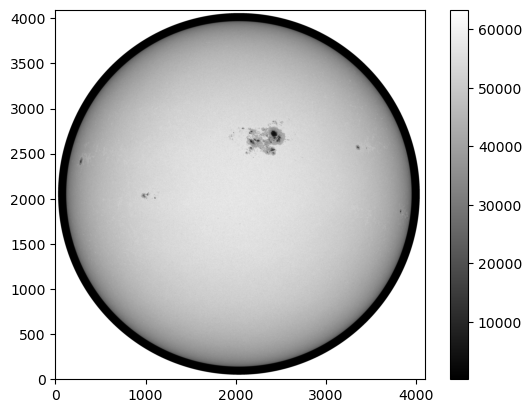

In [22]:
# Test code
fits_file = fits.open(test_path)
print(fits_file)

image_data = fits_file[1].data
print(image_data)

plt.figure()
plt.imshow(image_data, origin = "lower", cmap = "gray")
plt.colorbar()
plt.show()

In [2]:
with fits.open(test_path) as hdul:
    hdul.info()                                   # which HDU holds the image?
    hdu = hdul[1] if hdul[0].data is None else hdul[0]
    raw = hdu.data.astype(np.float32)             # float32: MPS cannot use float64
    hdr = hdu.header

print("shape:", raw.shape, "| dtype:", raw.dtype)
print("NaN pixels:", int(np.isnan(raw).sum()))
for key in ["CRPIX1", "CRPIX2", "CDELT1", "RSUN_OBS", "CROTA2", "CRLT_OBS", "T_REC"]:
    print(f"{key:9s}", hdr[key])

Filename: /Users/vinuradesilva/Documents/Projects/Sunspot detection with ML/Data/Raw/HMI/hmi.ic_720s.20141023_000000_TAI.1.continuum.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  COMPRESSED_IMAGE    1 CompImageHDU    112   (4096, 4096)   int16 (rescales to float32)   
shape: (4096, 4096) | dtype: float32
NaN pixels: 4184932
CRPIX1    2036.72986
CRPIX2    2049.87549
CDELT1    0.504359663
RSUN_OBS  964.3672485351562
CROTA2    180.013474
CRLT_OBS  5.25950098
T_REC     2014.10.23_00:00:00.000_TAI


In [3]:
# --- STAGE 1: flip, centre, radius, disc mask --------------------------------

# 1. Flip the image 180 degrees (two quarter turns)
img = np.rot90(raw, 2)

# 2. Radius in pixels, from the header: RSUN_OBS (arcsec) / CDELT1 (arcsec per pixel)
R = hdr["RSUN_OBS"] / hdr["CDELT1"]

# 3. Centre in the ORIGINAL image, in Python (0-based) pixel numbers
cx_raw = hdr["CRPIX1"] - 1
cy_raw = hdr["CRPIX2"] - 1

# 4. Centre after the flip (image side is 4096 pixels, indices run 0..4095)
cx = 4095 - cx_raw
cy = 4095 - cy_raw

# 5. Distance of every pixel from the centre, in solar radii
yy, xx = np.indices(img.shape)          # NOTE the order: rows (y) first, then columns (x)
r = np.sqrt((xx - cx)**2 + (yy - cy)**2) / R

# 6. Disc mask: True where we are on the Sun (strict, so mu = sqrt(1 - r^2) stays defined)
disc = r < 1

print(f"R = {R:.1f} px | centre after flip = ({cx:.1f}, {cy:.1f})")
print("disc pixels:", int(disc.sum()), "| pi*R^2 =", int(np.pi * R**2))

R = 1912.1 px | centre after flip = (2059.3, 2046.1)
disc pixels: 11485568 | pi*R^2 = 11485610


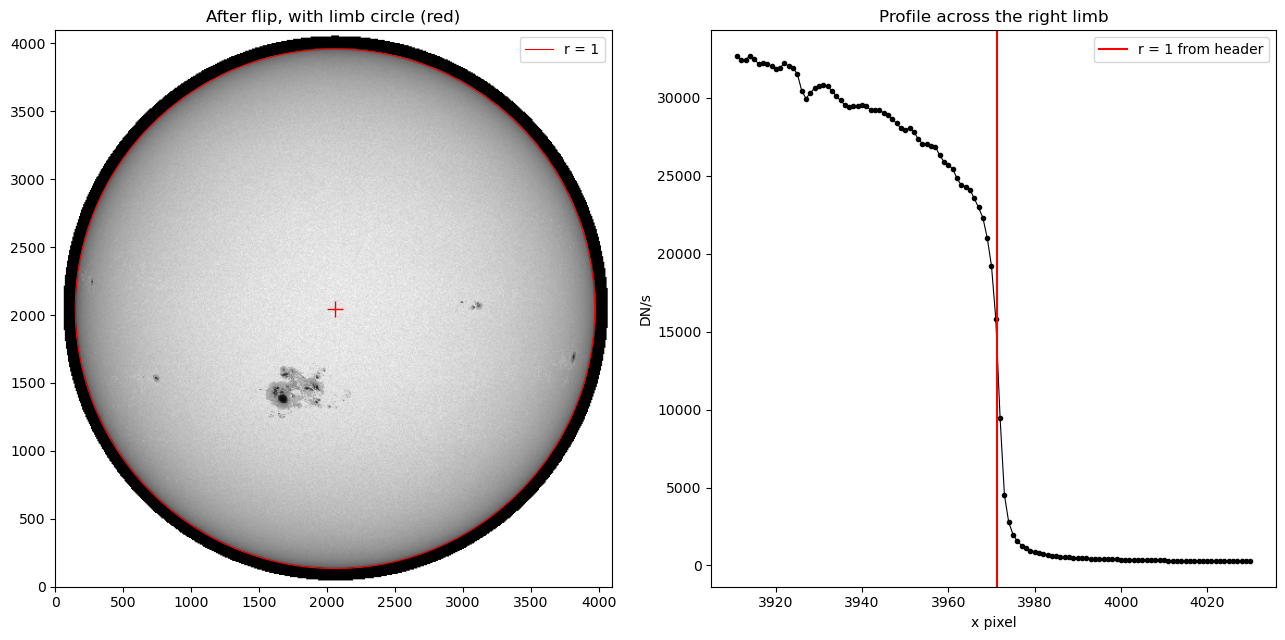

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))

# Left: whole image, downsampled by 8 for speed, with limb circle drawn at r = 1
ax[0].imshow(img[::8, ::8], cmap="gray", origin="lower", extent=[0, 4096, 0, 4096])
theta = np.linspace(0, 2 * np.pi, 400)
ax[0].plot(cx + R * np.cos(theta), cy + R * np.sin(theta), "r-", lw=0.8, label="r = 1")
ax[0].plot(cx, cy, "r+", ms=12)
ax[0].set_title("After flip, with limb circle (red)")
ax[0].legend()

# Right: horizontal brightness profile through the centre row, around the right limb
row = int(round(cy))
xs = np.arange(int(cx + R) - 60, int(cx + R) + 60)
ax[1].plot(xs, img[row, xs], "k.-", lw=0.8)
ax[1].axvline(cx + R, color="r", label="r = 1 from header")
ax[1].set_xlabel("x pixel"); ax[1].set_ylabel("DN/s")
ax[1].set_title("Profile across the right limb")
ax[1].legend()
plt.tight_layout()
plt.show()

In [5]:
# --- CHECK: does the header limb match the measured limb on all four sides? ---

def limb_offset(profile, pos, expected, inside_dir):
    """Outward offset (pixels) of the measured half-brightness edge from the expected limb.

    pos: pixel indices along the profile; expected: header limb position (pixels).
    inside_dir: +1 if the Sun lies at larger pos than the limb (left, bottom edges),
                -1 if at smaller pos (right, top edges).
    """
    d = pos - expected
    inside = np.median(profile[(inside_dir * d >= 20) & (inside_dir * d <= 50)])
    outside = np.median(profile[(-inside_dir * d >= 20) & (-inside_dir * d <= 50)])
    level = 0.5 * (inside + outside)               # halfway between disc and background

    near = np.where(np.abs(d) <= 20)[0]            # search only close to the expected edge
    for i in near[:-1]:
        a, b = profile[i] - level, profile[i + 1] - level
        if a * b <= 0 and profile[i] != profile[i + 1]:
            crossing = pos[i] + (level - profile[i]) / (profile[i + 1] - profile[i])
            return -inside_dir * (crossing - expected)   # positive = edge is outside the circle
    return np.nan

ix, iy = int(round(cx)), int(round(cy))
row_pos = np.arange(4096)                          # positions along a row or a column
sides = {
    "right":  (img[iy, :], cx + R, -1),
    "left":   (img[iy, :], cx - R, +1),
    "top":    (img[:, ix], cy + R, -1),
    "bottom": (img[:, ix], cy - R, +1),
}
for name, (profile, expected, inside_dir) in sides.items():
    off = limb_offset(profile, row_pos, expected, inside_dir)
    print(f"{name:6s} limb: measured edge is {off:+.2f} px outside the header circle")

right  limb: measured edge is -0.20 px outside the header circle
left   limb: measured edge is -0.33 px outside the header circle
top    limb: measured edge is -0.52 px outside the header circle
bottom limb: measured edge is +0.07 px outside the header circle


In [6]:
# --- CHECK: what do the pixels inside the disc mask look like? ---------------
vals = img[disc]                       # 1-D array of the ~11.5 million disc pixels

print("disc pixels:", vals.size)
print("NaN inside disc:", int(np.isnan(vals).sum()))
print("negative inside disc:", int((vals < 0).sum()))
print(f"min {vals.min():.0f} | 1st pct {np.percentile(vals, 1):.0f} | "
      f"median {np.median(vals):.0f} | 99th pct {np.percentile(vals, 99):.0f} | max {vals.max():.0f}")

disc pixels: 11485568
NaN inside disc: 0
negative inside disc: 0
min 2789 | 1st pct 24494 | median 48479 | 99th pct 58439 | max 63344


In [8]:
# --- STAGE 2: median intensity in rings of equal width in r ------------------

r_d = r[disc]                          # r of the disc pixels (1-D)
I_d = img[disc]                        # intensity of the disc pixels (1-D)

n_bins = 100                           # ring width = 0.01 solar radii
edges = np.linspace(0, 1, n_bins + 1)
centres = 0.5 * (edges[:-1] + edges[1:])

# 1. Ring number of every pixel: r in [0, 0.01) -> 0, [0.01, 0.02) -> 1, ... (integer array)
idx = (r_d * n_bins).astype(int)

med = np.zeros(n_bins)
spread = np.zeros(n_bins)              # 16th to 84th percentile range (about 2 sigma if Gaussian)
count = np.zeros(n_bins, dtype=int)
for k in range(n_bins):
    ring = I_d[idx == k]
    count[k] = ring.size
    # 2. Median intensity of this ring
    med[k] = np.median(ring)
    p16, p84 = np.percentile(ring, [16, 84])
    spread[k] = p84 - p16

# 3. mu = cos(theta) at the centre of each ring
mu = np.sqrt(1 - centres**2)

# 4. Intensity relative to the disc centre (innermost ring)
rel = med / med[0]

for k in [0, 10, 30, 50, 70, 80, 90, 95, 98, 99]:
    print(f"r = {centres[k]:.3f} | mu = {mu[k]:.3f} | pixels {count[k]:7d} | "
          f"median {med[k]:8.0f} | I/I_centre {rel[k]:.3f} | spread {spread[k]:6.0f}")

r = 0.005 | mu = 1.000 | pixels    1147 | median    56855 | I/I_centre 1.000 | spread   3250
r = 0.105 | mu = 0.994 | pixels   24117 | median    56636 | I/I_centre 0.996 | spread   3315
r = 0.305 | mu = 0.952 | pixels   70043 | median    55352 | I/I_centre 0.974 | spread   3582
r = 0.505 | mu = 0.863 | pixels  115989 | median    53066 | I/I_centre 0.933 | spread   2850
r = 0.705 | mu = 0.709 | pixels  161933 | median    48785 | I/I_centre 0.858 | spread   2232
r = 0.805 | mu = 0.593 | pixels  184912 | median    45281 | I/I_centre 0.796 | spread   1833
r = 0.905 | mu = 0.425 | pixels  207926 | median    39584 | I/I_centre 0.696 | spread   1335
r = 0.955 | mu = 0.297 | pixels  219340 | median    34559 | I/I_centre 0.608 | spread   1242
r = 0.985 | mu = 0.173 | pixels  226282 | median    28853 | I/I_centre 0.507 | spread   2043
r = 0.995 | mu = 0.100 | pixels  228516 | median    24791 | I/I_centre 0.436 | spread   5061


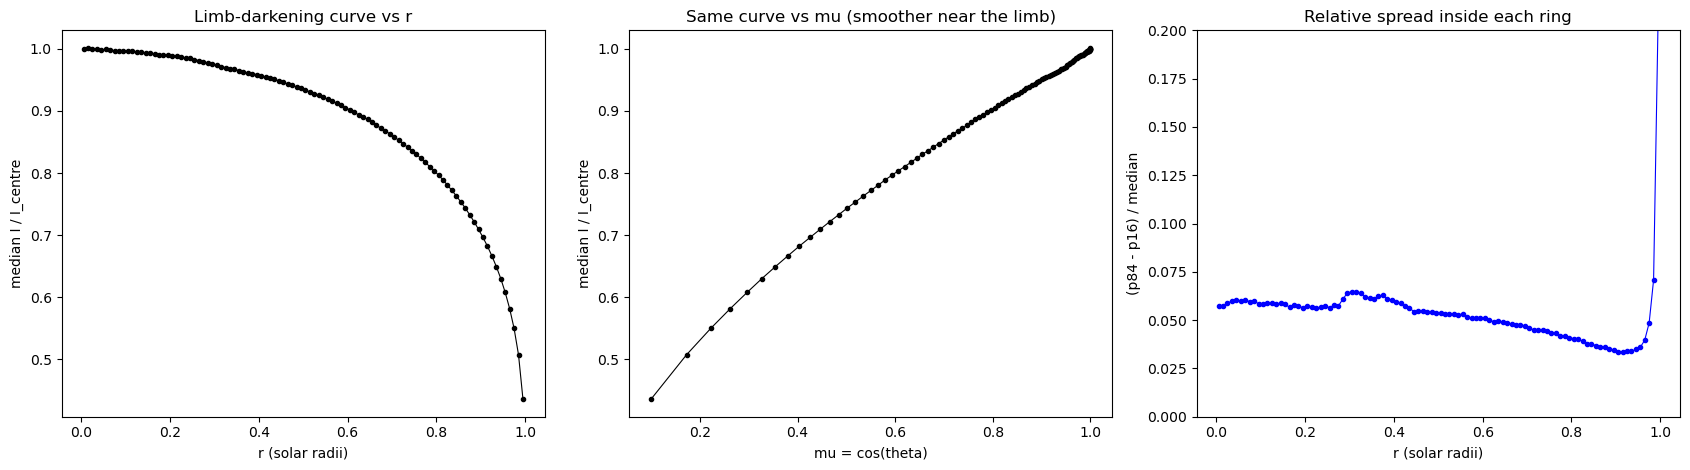

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

ax[0].plot(centres, rel, "k.-", lw=0.8)
ax[0].set_xlabel("r (solar radii)"); ax[0].set_ylabel("median I / I_centre")
ax[0].set_title("Limb-darkening curve vs r")

ax[1].plot(mu, rel, "k.-", lw=0.8)
ax[1].set_xlabel("mu = cos(theta)"); ax[1].set_ylabel("median I / I_centre")
ax[1].set_title("Same curve vs mu (smoother near the limb)")

ax[2].plot(centres, spread / med, "b.-", lw=0.8)
ax[2].set_xlabel("r (solar radii)"); ax[2].set_ylabel("(p84 - p16) / median")
ax[2].set_title("Relative spread inside each ring")
ax[2].set_ylim(0, 0.2)

plt.tight_layout()
plt.show()

In [10]:
# --- STAGE 3: polynomial fit in mu for several candidate cut radii -----------

cuts = [0.90, 0.95, 0.97, 0.98, 0.99]
deg = 4
interior = centres < 0.90              # the same reliable rings for every candidate

fits = {}
for cut in cuts:
    # 1. Rings used for the fit: those whose centre lies inside the cut (boolean array)
    use = centres < cut

    # 2. Fit med as a polynomial of mu using only those rings
    coef = np.polyfit(mu[use], med[use], deg)

    # 3. Model value at the centre of EVERY ring (including rings we did not fit)
    pred = np.polyval(coef, mu)

    # 4. Relative residual of every ring: (data - model) / data
    resid = (med - pred) / med

    fits[cut] = (coef, pred, resid)
    rms_in = np.sqrt(np.mean(resid[interior] ** 2))
    print(f"cut {cut:.2f} | rings used {use.sum():3d} | interior rms {100 * rms_in:.3f} % | "
          f"residual at r=0.965, 0.975, 0.985, 0.995: "
          + " ".join(f"{100 * resid[k]:+6.2f}%" for k in [96, 97, 98, 99]))

cut 0.90 | rings used  90 | interior rms 0.088 % | residual at r=0.965, 0.975, 0.985, 0.995:  -6.34% -10.23% -17.63% -37.53%
cut 0.95 | rings used  95 | interior rms 0.094 % | residual at r=0.965, 0.975, 0.985, 0.995:  -1.16%  -2.26%  -4.61% -11.87%
cut 0.97 | rings used  97 | interior rms 0.099 % | residual at r=0.965, 0.975, 0.985, 0.995:  -0.24%  -0.72%  -1.88%  -6.04%
cut 0.98 | rings used  98 | interior rms 0.102 % | residual at r=0.965, 0.975, 0.985, 0.995:  +0.00%  -0.26%  -1.00%  -4.03%
cut 0.99 | rings used  99 | interior rms 0.106 % | residual at r=0.965, 0.975, 0.985, 0.995:  +0.15%  +0.06%  -0.31%  -2.36%


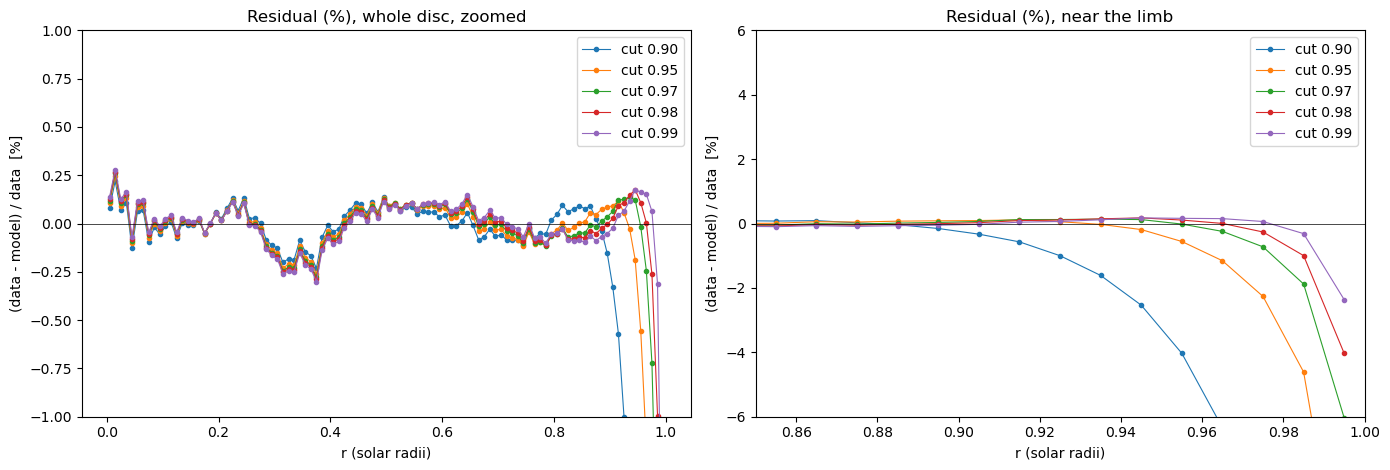

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for cut in cuts:
    coef, pred, resid = fits[cut]
    ax[0].plot(centres, 100 * resid, ".-", lw=0.8, label=f"cut {cut:.2f}")
    ax[1].plot(centres, 100 * resid, ".-", lw=0.8, label=f"cut {cut:.2f}")
ax[0].set_ylim(-1, 1);  ax[0].set_title("Residual (%), whole disc, zoomed")
ax[1].set_xlim(0.85, 1.0); ax[1].set_ylim(-6, 6); ax[1].set_title("Residual (%), near the limb")
for a in ax:
    a.axhline(0, color="k", lw=0.5)
    a.set_xlabel("r (solar radii)"); a.set_ylabel("(data - model) / data  [%]")
    a.legend()
plt.tight_layout()
plt.show()

In [13]:
# --- STAGE 4: divide every disc pixel by the model ---------------------------

# 1. Coefficients of the chosen cut (0.99), taken from the dictionary by key
coef_final = fits[0.99][0]                      # NEW: element 0 of the tuple (coef, pred, resid)

# 2. mu of every disc pixel, from its own r
mu_d = np.sqrt(1 - r_d**2)                      # NEW: per-pixel mu, not per-ring

# 3. Model value at every disc pixel
model_d = np.polyval(coef_final, mu_d)          # NEW: normal-Sun brightness at each pixel

# 4. Corrected intensity: data divided by model
flat_d = I_d / model_d                          # NEW: 1 = normal Sun, <1 darker, >1 brighter

flat = np.zeros(img.shape, dtype=np.float32)    # off-disc stays exactly 0
flat[disc] = flat_d.astype(np.float32)          # float32 for the MPS backend

print("model range on disc: %.0f to %.0f DN/s" % (model_d.min(), model_d.max()))
print("flat on disc: min %.3f | 1st pct %.3f | median %.4f | 99th pct %.3f | max %.3f"
      % (flat_d.min(), np.percentile(flat_d, 1), np.median(flat_d),
         np.percentile(flat_d, 99), flat_d.max()))
print("off-disc pixels equal to 0:", int((flat[~disc] == 0).sum()), "of", int((~disc).sum()))

model range on disc: 20119 to 56777 DN/s
flat on disc: min 0.051 | 1st pct 0.881 | median 0.9996 | 99th pct 1.061 | max 1.237
off-disc pixels equal to 0: 5291648 of 5291648


rings 0-89  : max |median - 1| = 0.298 %
rings 90-98 : max |median - 1| = 0.359 %
ring 99     : median - 1 = -2.57 %


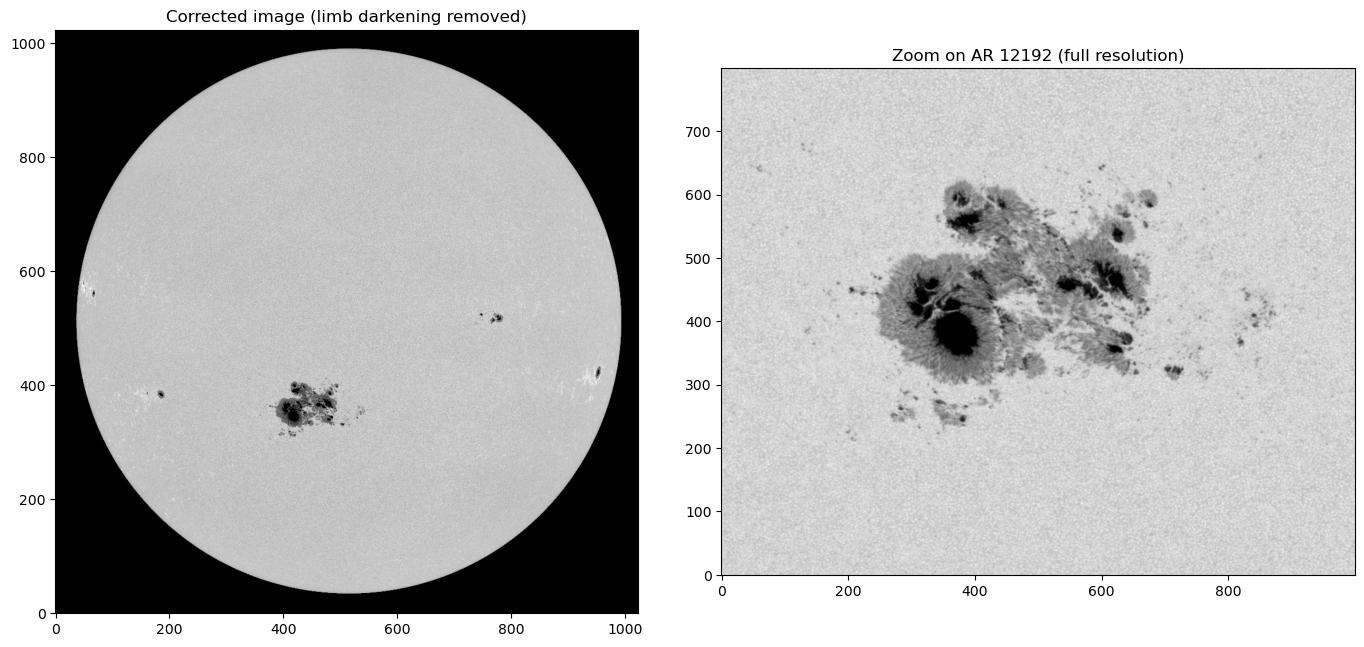

In [14]:
# --- CHECK: are the ring medians of the corrected image flat at 1? -----------
ring_med = np.array([np.median(flat_d[idx == k]) for k in range(n_bins)])
dev = ring_med - 1
print(f"rings 0-89  : max |median - 1| = {100 * np.abs(dev[:90]).max():.3f} %")
print(f"rings 90-98 : max |median - 1| = {100 * np.abs(dev[90:99]).max():.3f} %")
print(f"ring 99     : median - 1 = {100 * dev[99]:+.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
ax[0].imshow(flat[::4, ::4], cmap="gray", origin="lower", vmin=0.5, vmax=1.15)
ax[0].set_title("Corrected image (limb darkening removed)")
ax[1].imshow(flat[1000:1800, 1300:2300], cmap="gray", origin="lower", vmin=0.3, vmax=1.15)
ax[1].set_title("Zoom on AR 12192 (full resolution)")
plt.tight_layout()
plt.show()

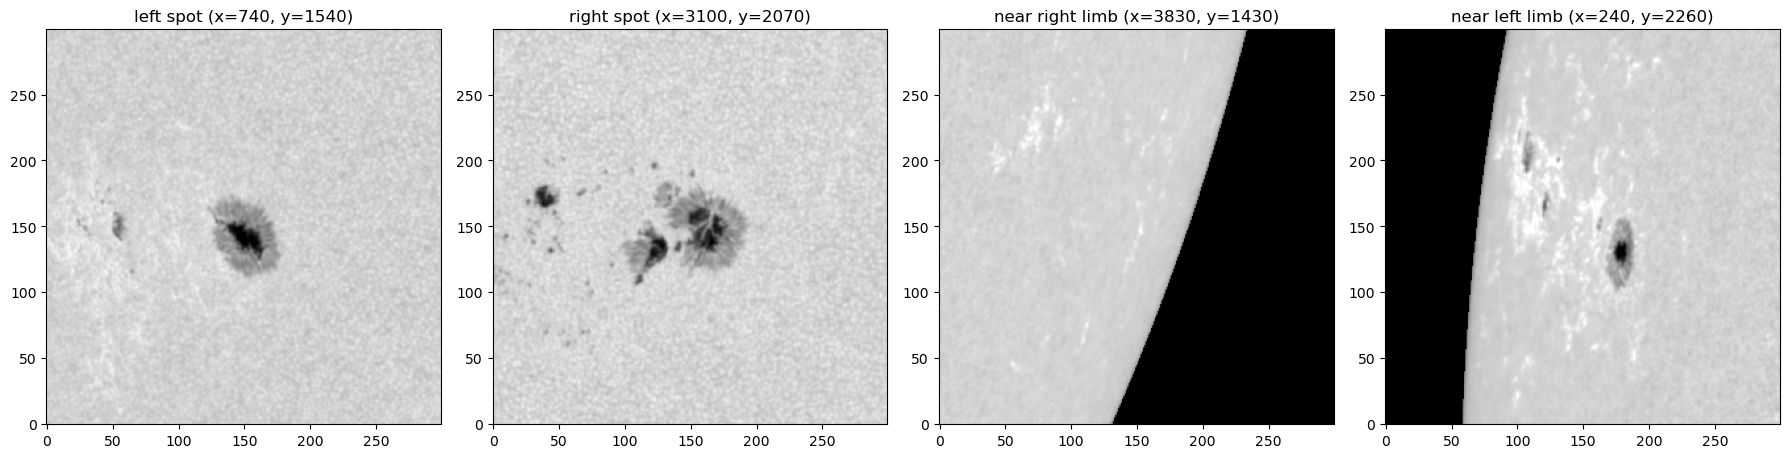

In [15]:
# --- LOOK: zoom on the smaller spots (centres are estimates from the downsampled view) ---
centres_xy = {
    "left spot": (740, 1540),
    "right spot": (3100, 2070),
    "near right limb": (3830, 1430),
    "near left limb": (240, 2260),
}
half = 150                                       # crop is 300 x 300 pixels

fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
for a, (name, (x0, y0)) in zip(ax, centres_xy.items()):
    crop = flat[y0 - half:y0 + half, x0 - half:x0 + half]
    a.imshow(crop, cmap="gray", origin="lower", vmin=0.3, vmax=1.15)
    a.set_title(f"{name} (x={x0}, y={y0})")
plt.tight_layout()
plt.show()